# Lesson 9: Thermodynamics I: Electrochemical Potential and the Nernst Equation
All fundamental concepts in chemistry can be applied to electrochemistry, but the mathematics must be validated. We will do that validation here, and the reward is the single most useful equation in the course.

Today's topics:
- Chemical potential, electrochemical potential and voltage
- Applying them to reactions with and without electron transfer
- The Nernst equation, formal potentials and open-circuit potential

**Reference:**
- Sections 2.1 and 2.2 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from ipywidgets import interact, widgets
import schemdraw
import schemdraw.elements as elm

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE   # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

# 1. Fundamental Thermodynamics
**Chemical potential** ( $\large \mu_i^\alpha$ ) is a fundamental concept in chemical thermodynamics. It is the change in the free energy ( $\delta G$ ) of a system upon a change in the number of particles ( $\delta n_i$ ) of a given type in the system:

$
\large \mu_i^\alpha = \left( \frac{\delta G}{\delta n_i}\right)_{T,P,n_{j \neq i}}
$

<div class="alert alert-block alert-success">
<b>Electrochemical potential:</b> a conceptual modification that allows mathematical separation of the contributions from the electrical environment (i.e. electrostatic effects from the surrounding medium).
</div>

The electrochemical potential can be represented analagous to the chemical potential:

$
\large \bar{\mu}_i^\alpha = \left( \frac{\delta \bar{G}}{\delta n_i}\right)_{T,P,n_{j \neq i}}
$

But the **bar-notation** indicates that the terms are modified:

$
\large \bar{\mu}_i^\alpha = \mu_i^\alpha + z_i F \phi^\alpha
$

Where:
- $i$ : a species in the system
- $\alpha$ : phase (eg, a solution, a solid, a liquid, etc.)
- z $_i$ : charge on species $i$ 
- $\phi^\alpha$ : potential (voltage) in $\alpha$ 

## Properties of $\bar{\mu}_i^\alpha$ :

|Number | Condition | Property |
|--- |--- |--- |
| 1 | Species $i$ is uncharged | $\bar{\mu}_i^\alpha=\mu_i^\alpha$ |
| 2 | Always | $\mu_i^\alpha=\mu_i^{0,\alpha} + RT ln(a_i^\alpha)$ |
| 3 | Pure phases at unity activity<br>(eg, solids, gases, pure liquids... $a_i^\alpha = 1$ ) | $\bar{\mu}_i^\alpha=\mu_i^{0, \alpha}$ |
| 4 | Electrons in a metal | $\bar{\mu}_i^\alpha=\mu_i^{0, \alpha}-F\phi^\alpha$ |
| 5 | Species $i$ in equilibrium between two phases ( $\alpha$ , $\beta$ ) | $\bar{\mu}_i^\alpha=\bar{\mu}_i^\beta$ |

## Application

### Example 1: Reaction of two phases with no electron transfer.
- Dissolution of AgCl from the surface of a silver-silver chloride reference electrode (SSCE).

$
\large AgCl_{(s)} \rightleftharpoons Ag^+_{(aq)} + Cl^-_{(aq)}
$

Apply **property 5**:

$
\large \bar{\mu}_{AgCl}^{AgCl} = \bar{\mu}_{Ag^+}^{aq} + \bar{\mu}_{Cl^-}^{aq}
$

Substitute pure phases using **property 3** and expand using **definition** and **property 2**:

$
\large \mu_{AgCl}^{0, AgCl} = \mu_{Ag^+}^{0, aq} + RTln(a_{Ag^+}^{aq}) + F\phi^{aq} + \mu_{Cl^-}^{0, aq} + RTln(a_{Cl^-}^{aq}) - F\phi^{aq}
$

Collect terms and isolate standard values:

$
\large \mu_{AgCl}^{0, AgCl} - \mu_{Ag^+}^{0, aq} - \mu_{Cl^-}^{0, aq} = RTln(a_{Ag^+}^{aq}) + RTln(a_{Cl^-}^{aq})
$

Simplify:

$
\large \mu_{AgCl}^{0, AgCl} - \mu_{Ag^+}^{0, aq} - \mu_{Cl^-}^{0, aq} = RTln(a_{Ag^+}^{aq}a_{Cl^-}^{aq})
$

Recognize equilibrium constant for dissolution, $K_{sp}$ :

$
\large K_{sp} = \frac{a_{Ag^+}a_{Cl^-}}{a_{AgCl}} = a_{Ag^+}a_{Cl^-}
$

Substitute:

$
\large \mu_{AgCl}^{0, AgCl} - \mu_{Ag^+}^{0, aq} - \mu_{Cl^-}^{0, aq} = RTln(K_{sp})
$

Recall that the standard Gibbs energy of reaction is the difference in standard chemical potentials of the products ( $\mu^0_p$ ) and the reactants ( $\mu^0_r$ ), each weighted by its stoichiometric coefficient ( $\nu$ ):

$
\large \Delta G^0_{rxn} = \sum{\nu_p \mu^0_p} - \sum{\nu_r \mu^0_r}
$

Therfore:

$
\large \Delta G^0 = -RTln(K_{sp})
$

<div class="alert alert-block alert-success">
<b>The net result</b>: When no charge transfer occurs there is no thermodynamic dependence on potential.
</div>


Take care: this does not mean that such reactions CANNOT exert some influence over electrochemical reactions. Lets consider the **silver-silver chloride reference electrode** further.

The fundamental reaction that it relies upon is the reduction of silver chloride:

$
\large AgCl_{(s)} + e^- \rightleftharpoons Cl^-_{aq} + Ag_{(s)}
$

While the dissolution of the required AgCl solid is not directly affected by application of a voltage, the $K_{sp}$ value DOES impact the equilibrium potential for the half-cell reaction. This happens because of the shared anion between the two reactions. Changes in $K_{sp}$ , for example by changes in temperature, will result in a change in activity of chloride ions, which alters the equilibrium of the reference half-cell reaction. Changes in the concentration of the electrolyte solution in the reference electrode will similarly affect the measured potential. User beware!

### Example 2: A complete electron transfer reaction.

- Consider coupling the oxidation of zinc with the silver-silver chloride reference electrode reaction (Cu and Cu' denote different electrode surfaces).

$
\large Zn + 2AgCl + 2e^-_{Cu'} \rightleftharpoons Zn^{2+} + 2Ag + 2Cl^- + 2e^-_{Cu}
$


<div class="alert alert-block alert-info">
<b>Activity:</b> Draw a 2-electrode electrochemical cell where this reaction is taking place. Determine the electrochemical potential.
</div>

$
\large \bar{\mu}_{Zn}^{Zn} + 2\bar{\mu}_{AgCl}^{AgCl} + 2\bar{\mu}_{e}^{Cu'} = \bar{\mu}_{Zn^{2+}}^{aq} + 2\bar{\mu}_{Ag}^{Ag} + 2\bar{\mu}_{Cl^{-}}^{aq} + 2\bar{\mu}_{e^-}^{Cu}
$

Rearrange to isolate electrons:

$
\large 2(\bar{\mu}_{e^-}^{Cu'} - \bar{\mu}_{e^-}^{Cu}) = 2\bar{\mu}_{Ag}^{Ag} - \bar{\mu}_{Zn}^{Zn} - 2\bar{\mu}_{AgCl}^{AgCl} + 2\bar{\mu}_{Cl^{-}}^{aq} + \bar{\mu}_{Zn^{2+}}^{aq}
$

Apply **property 4** to electrons:

$
\large 2(\bar{\mu}_{e^-}^{Cu'} - \bar{\mu}_{e^-}^{Cu}) = -2(F\phi^{Cu'} - F\phi^{Cu}) = -2FE
$

Expand with **properties 2 and 3** and group strategically:

$
\large -2FE = 2\mu_{Ag}^{0, Ag} - \mu_{Zn}^{0, Zn} - 2\mu_{AgCl}^{0, AgCl} + 2[\mu_{Cl^-}^{0, aq} + RTln(a_{Cl^-}^{aq}) - F\phi^{aq}] + [\mu_{Zn^{2+}}^{0, aq} + RTln(a_{Zn^{2+}}^{aq}) + 2F\phi^{aq}]
$

Recall the *standard* Gibbs energy definition:

$
\large \Delta G^0 = 2\mu_{Ag}^{0, Ag} + 2\mu_{Cl^-}^{0, aq} + \mu_{Zn^{2+}}^{0, aq} - \mu_{Zn}^{0, Zn} - 2\mu_{AgCl}^{0, AgCl} = -2FE^0
$

Substitute equations and simplify:

$
\large -2FE = -2FE^0 + RTln(a_{Zn^{2+}}^{aq}(a_{Cl^{-}}^{aq})^2)
$

Divide by $-2F$ :

$
\large E = E^0 - \frac{RT}{2F}ln(a_{Zn^{2+}}^{aq}(a_{Cl^{-}}^{aq})^2)
$

<div class="alert alert-block alert-success">
<b>The net result</b>: Application of electrochemical potential to an electron transfer results in the <b>Nernst Equation</b>.
</div>

# 2. The Nernst Equation

The Nernst equation can be applied to full-cell reactions as done above, or to individual half-cell reactions when using a 3-electrode cell.

The behavior can be safely generalized:

$
\large O + ne^- \rightleftharpoons R
$

Due to logarithmic identities, there are four different ways to write out the Nernst equation in its logarithmic form:

$
\large E = E^0 - \frac{RT}{nF}ln\left[\frac{a_R}{a_O}\right]
$

$
\large E = E^0 - 2.303\frac{RT}{nF}log\left[\frac{a_R}{a_O}\right]
$

$
\large E = E^0 + \frac{RT}{nF}ln\left[\frac{a_O}{a_R}\right]
$

$
\large E = E^0 + 2.303\frac{RT}{nF}log\left[\frac{a_O}{a_R}\right]
$

Where:
- $E$ : Equilibrium potential
- $E^0$ : Standard reduction potential
- $F$ : Faraday's constant
- $n$ : electron stoichiometry
- $T$ : temperature (Kelvin)
- $R$ : Gas constant
- $a_i$ : activity of $i$ 

The standard reduction potentials are typically reported in units of 
- *V vs. NHE*, measured under standard conditions (ie, solution containing 1 M H $^+$ )
- *V vs. SHE*, a theoretical value

These forms of the Nernst equation all involve the *activity* of species, which we can't directly measure. We would like to work with *concentrations*, which we can measure and control. We can modify the equation as is traditionally done in chemistry - by defining an activity coefficient, $\gamma_i$ :

$
\large a_i = \gamma_i[i]
$

The Nernst equation can then be rewritten as:

$
\large E = E^0 - \frac{RT}{nF}ln\left[\frac{\gamma_R[R]}{\gamma_O[O]}\right]
$

This can be rearranged:

$
\large E = E^0 - \frac{RT}{nF}ln\left[\frac{\gamma_R}{\gamma_O}\right] - \frac{RT}{nF}ln\left[\frac{[R]}{[O]}\right]
$

 $\gamma_i$ values are constants at fixed ionic strength (and temperature), so they can be combined with $E^0$ to yield a new constant that is referred to as the **formal potential**:

$
\large E^{0'} = E^0 - \frac{RT}{nF}ln\left[\frac{\gamma_R}{\gamma_O}\right]
$

The result is a version of the Nernst equation that utilizes concentrations:

$
\large E = E^{0'} - \frac{RT}{nF}ln\left[\frac{[R]}{[O]}\right]
$

The **formal potential** is an important concept. The theory surrounding standard reduction potentials relies upon discussion of activities, which aren't experimentally measured. The conversion to formal potential links the theory to real-world experiments.

## Seeing the Nernst Equation

Written as an equation, the Nernst relationship is a statement about a ratio. Plotted, it is a shape you will meet again in almost every experiment for the rest of the course: a sigmoid that switches a couple from fully reduced to fully oxidized over a few tens of millivolts.

Rearranging the concentration form for the fraction of the couple that is oxidized gives:

$
\large \frac{[O]}{[O]+[R]} = \frac{1}{1 + e^{-nf(E-E^{0'})}}
$

where $f = F/RT$ . Only three things can move this curve: $E^{0'}$ slides it along the potential axis, and $n$ and $T$ set how sharply it turns. Everything else in electrochemistry is layered on top of this shape.

In [2]:
# echem.nernst_fraction_oxidized(E, e_formal, n, temperature) applies the
# equation above; echem.nernstian_slope(n, temperature) returns 2.303RT/nF.
# help(echem.nernst_fraction_oxidized)

POTENTIAL = np.linspace(-0.4, 0.4, 400)     # V, on whatever scale E0' is quoted

@interact(n=widgets.IntSlider(value=1, min=1, max=3, description=r'$n$'),
          temperature=widgets.FloatSlider(value=298, min=273, max=373, step=5,
                                          description=r'$T$ /K'),
          e_formal=widgets.FloatSlider(value=0.0, min=-0.2, max=0.2, step=0.01,
                                       readout_format='.2f',
                                       description=r"$E^{0'}$ /V"))
def plot_nernst_curve(n, temperature, e_formal):
    '''The Nernst equation as a curve (left) and as a straight line (right).'''
    frac_o = echem.nernst_fraction_oxidized(POTENTIAL, e_formal, n, temperature)
    frac_r = echem.nernst_fraction_reduced(POTENTIAL, e_formal, n, temperature)
    slope = echem.nernstian_slope(n, temperature)       # V per decade

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)

    # Left: the fractions themselves.
    ax1.plot(POTENTIAL, frac_o, color=echem.color(0), label='O')
    ax1.plot(POTENTIAL, frac_r, color=echem.color(1), label='R')
    ax1.plot([e_formal], [0.5], 'o', color='black', markersize=3)
    ax1.annotate(r"$E^{0'}$", (e_formal + 0.01, 0.55), fontsize=6)
    ax1.set_xlabel(r'$E$ /V')
    ax1.set_ylabel(r'fraction of couple')
    ax1.set_ylim(-0.05, 1.05)
    ax1.legend(fontsize=6, loc='center left')

    # Right: the same numbers plotted the way the Nernst equation is written.
    with np.errstate(divide='ignore', invalid='ignore'):
        log_ratio = np.log10(frac_o/frac_r)
    ax2.plot(log_ratio, POTENTIAL, color=echem.color(0))
    ax2.plot([0], [e_formal], 'o', color='black', markersize=3)
    ax2.set_xlim(-4, 4)
    ax2.set_xlabel(r'$log([O]/[R])$')
    ax2.set_ylabel(r'$E$ /V')
    ax2.annotate(f'{1000*slope:.1f} mV/decade', (-3.8, e_formal + 0.28), fontsize=6)

    print(f'RT/nF        = {1000*R*temperature/(n*F):6.2f} mV')
    print(f'2.303RT/nF   = {1000*slope:6.2f} mV per decade of [O]/[R]')
    print(f"E0' to 99% O = {slope*2:6.2f} V  (two decades past the midpoint)")

interactive(children=(IntSlider(value=1, description='$n$', max=3, min=1), FloatSlider(value=298.0, descriptio…

<div class="alert alert-block alert-info">
<b>Activity:</b> Set $n$ = 1 and move the temperature from 273 K to 373 K.
<br>
Which way does the curve tip, and by how many mV per decade does the slope change over that range? Then explain why an ion sensor calibrated in an ice bath and used at body temperature reports the wrong concentration even though nothing about the chemistry has changed.
</div>

- Effect of raising $T$ : ANSWER
- Change in slope, 273 K to 373 K: ANSWER
- Why the sensor is wrong: ANSWER

The field can become somewhat confusing because there exists a number of measurable potentials that are assigned specific names. For now, the other important one to be introduced is the **open-circuit potential**.

<div class="alert alert-block alert-success">
<b>Open-circuit potential ( $E_{OC}$ )</b>: The equilibrium potential of an unperturbed system. Can be measured as the voltage difference between two electrodes when no current is allowed to flow.
</div>

 $E_{OC}$ provides a measure of the equilibrium of electrochemical reactions at the electrode-solution interface. Changes in $E_{OC}$ signify chemical changes at the surface, a feature that is exploited for numerous chemical sensors, but also to study reaction mechanisms that occur spontaneously.



## Potentiometry: Measuring $E_{OC}$ on Purpose

A potentiometric measurement is the Nernst equation read backwards. Instead of setting a potential and asking what the concentration ratio must become, we hold the current at zero, let the interface settle at its own equilibrium, and read the potential to learn what the ratio already is:

$
\large E_{OC} = E^{0'} + \frac{2.303RT}{nF}log\left[\frac{[O]}{[R]}\right]
$

The coefficient $2.303RT/nF$ is worth committing to memory. At 298 K it is **59.2 mV per decade** for $n$ = 1, and 29.6 mV for $n$ = 2. Any sensor that returns this slope is behaving exactly as the Nernst equation demands and is called **Nernstian**; one that returns noticeably less is **sub-Nernstian**, and the deficit is the first thing an analyst reports.

The most familiar example is the pH electrode, which delivers 59.2 mV per pH unit at 298 K. We will take that apart properly in Lesson 15, once we have membrane potentials; for now the point is that its calibration slope is nothing more than $2.303RT/F$ .

apparent pH minus true pH, at pH 7:  -1.10 pH units
apparent pH minus true pH, at pH 12: -1.86 pH units


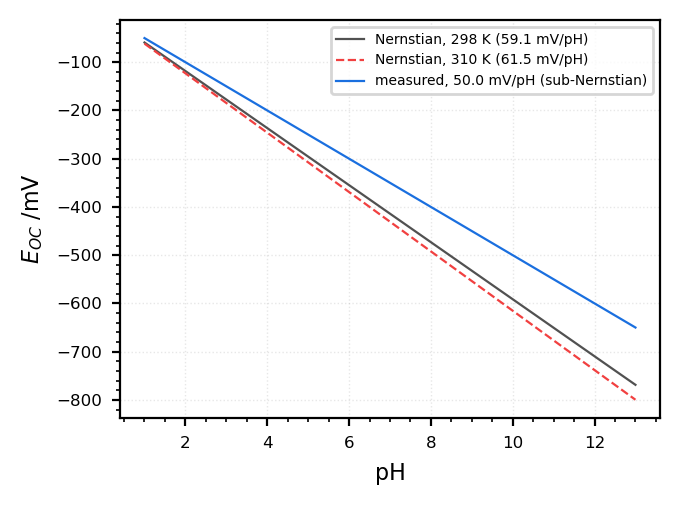

In [3]:
# A calibration curve is a straight line whose slope is 2.303RT/nF.  Comparing
# a measured slope against that ideal is how a potentiometric sensor is judged.
PH = np.linspace(1, 13, 50)
E_ZERO = 0.0                                # reading of the ideal probe at pH 0

ideal_298 = E_ZERO - echem.nernstian_slope(n=1, temperature=298)*PH
ideal_310 = E_ZERO - echem.nernstian_slope(n=1, temperature=310)*PH
measured = E_ZERO - 0.0500*PH               # a tired probe: 50.0 mV per decade

fig = plt.figure()
ax = plt.subplot(111)
ax.plot(PH, 1000*ideal_298, color=echem.color(0),
        label=f'Nernstian, 298 K ({1000*echem.nernstian_slope():.1f} mV/pH)')
ax.plot(PH, 1000*ideal_310, color=echem.color(1), linestyle='--',
        label=f'Nernstian, 310 K ({1000*echem.nernstian_slope(temperature=310):.1f} mV/pH)')
ax.plot(PH, 1000*measured, color=echem.color(2),
        label='measured, 50.0 mV/pH (sub-Nernstian)')
ax.set_xlabel('pH')
ax.set_ylabel(r'$E_{OC}$ /mV')
ax.legend(fontsize=5)

# If we trust the ideal slope, the tired probe reports the wrong pH.  The error
# is (apparent pH - true pH), and it grows the further we work from calibration.
error = (ideal_298 - measured)/echem.nernstian_slope()
print(f'apparent pH minus true pH, at pH 7:  {error[np.argmin(abs(PH-7))]:+.2f} pH units')
print(f'apparent pH minus true pH, at pH 12: {error[np.argmin(abs(PH-12))]:+.2f} pH units')

### What $E_{OC}$ Cannot Tell You

 $E_{OC}$ is only a thermodynamic quantity when the interface really is at equilibrium with a single couple. Three situations break that assumption, and all three are common:

- **Mixed potentials.** If two different couples are active at the same surface, the electrode settles where the anodic current of one exactly cancels the cathodic current of the other. The resulting $E_{OC}$ is a *kinetic* compromise between two reactions and obeys no Nernst equation at all. This is the basis of corrosion potentials, which we return to in Lesson 12.
- **Sluggish couples.** A reaction with slow electron transfer may take hours to reach equilibrium, or never get there. The measured potential drifts, and the drift rate tells you about kinetics rather than thermodynamics.
- **Junction potentials.** The reference electrode contacts the test solution through a frit, and the ion flow across that boundary adds its own potential to every reading. Typically a few millivolts, occasionally tens; Lesson 15 shows how to estimate and minimise it.

<div class="alert alert-block alert-danger">
<b>Take care:</b> a stable $E_{OC}$ is not proof of equilibrium. It is only proof that nothing is <i>changing</i>. A mixed potential can be extremely stable while the electrode quietly corrodes.
</div>

<div class="alert alert-block alert-info">
<b>Activity:</b> Write out the four algebraic forms of the Nernst equation from memory, then check them against the cells above.
<br>
For each form, say in one phrase what situation it is the most convenient one to use in.
</div>

1. Form: ANSWER &nbsp;&nbsp; convenient when: ANSWER
2. Form: ANSWER &nbsp;&nbsp; convenient when: ANSWER
3. Form: ANSWER &nbsp;&nbsp; convenient when: ANSWER
4. Form: ANSWER &nbsp;&nbsp; convenient when: ANSWER

<div class="alert alert-block alert-danger">
<b>Check your units!</b>
<br>
Confirm that $RT/nF$ comes out in volts, and work out the numerical value it takes at 298 K for $n = 1$ . You will use that number for the rest of the course.
</div>

---
# Group Activity: The Derivation Relay

Everything in this lesson came from the same process: write $\bar{\mu}$ for every species, apply properties 1 to 5, and collect terms. Do this for the **lead-acid battery**, the chemistry used in traditional vehicle batteries.

$
\large PbO_2 + HSO_4^- + 3H^+ + 2e^-_{Pt} \rightleftharpoons PbSO_4 + 2H_2O \quad (E^0 = 1.69\ V)
$

$
\large PbSO_4 + H^+ + 2e^-_{Pb} \rightleftharpoons Pb + HSO_4^- \quad (E^0 = -0.36\ V)
$

**Form four groups.** Each group does one stage and hands its result to the next; the receiving group must check the work it is given before building on it.

1. **Group A: set it up.** Combine the two half reactions into the overall cell reaction and confirm the electron count. Write the equilibrium statement in $\bar{\mu}$ terms, with the electrons in the two electrodes kept distinct ( $e^-_{Pb}$ and $e^-_{Pt}$ ).
2. **Group B: substitute.** Apply property 3 to the pure solids, property 2 to the dissolved species, and property 4 to the electrons. Take $a_{H_2O}$ = 1.
3. **Group C: collect.** Gather the standard chemical potentials into $\Delta G^0$ , confirm the $\phi^{aq}$ terms cancel, and identify $-nFE^0$ .
4. **Group D: finish and evaluate.** Isolate $E$ to reach the Nernst equation for this cell, then use the code cell below to evaluate it.

Then, as a class:

<div class="alert alert-block alert-info">
<b>The payoff:</b> a lead-acid cell is charged when the acid is roughly 5 M and discharged near 2 M. Use your derived equation to predict the voltage difference between those two states, for a single cell and for a six-cell 12 V battery.
<br>
Why can a garage mechanic judge the state of charge of a lead-acid battery with a <i>hydrometer</i>, which measures nothing but the density of the acid?
</div>

In [4]:
# Fill in the expression your groups derived, then run this cell.
#
# Hint: with a_H2O = 1 and both acid species at activity a, every group should
# arrive at a result of the form  E = E0 + (RT/nF)*ln(a**p)  for some power p.
# Work out n and p from your derivation; do not take them on faith from here.

E_STANDARD = 1.69 - (-0.36)         # V, from the two half cells above
N_ELECTRONS = 2                     # electrons in the overall reaction

def cell_potential(activity, power):
    '''Equilibrium potential of one lead-acid cell at the given acid activity.'''
    return E_STANDARD + (R*T/(N_ELECTRONS*F))*np.log(activity**power)

POWER = 1                           # <-- placeholder: replace with the power YOU derived

charged = cell_potential(5.0, POWER)
discharged = cell_potential(2.0, POWER)

print(f'Charged   (a = 5.0): {charged:.3f} V per cell,  {6*charged:.2f} V for six cells')
print(f'Discharged (a = 2.0): {discharged:.3f} V per cell,  {6*discharged:.2f} V for six cells')
print(f'Difference:           {1000*(charged - discharged):.0f} mV per cell, '
      f'{1000*6*(charged - discharged):.0f} mV for the battery')

Charged   (a = 5.0): 2.071 V per cell,  12.42 V for six cells
Discharged (a = 2.0): 2.059 V per cell,  12.35 V for six cells
Difference:           12 mV per cell, 71 mV for the battery
